# Прогноз продаж Bathroom Metal Sign

Возьмём подготовленный дневной ряд товара 82580 из Online Retail. В CSV дни без продаж записаны нулями, дубли, отмены и возвраты убраны. Соберём полные недели и месяцы.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor
from statsmodels.tsa.holtwinters import Holt

folder = Path.cwd()
if (folder / "PavelPaha" / "data" / "daily.csv").is_file():
    folder /= "PavelPaha"

daily = pd.read_csv(folder / "data/daily.csv", index_col="date", parse_dates=["date"])["units"]
daily = daily.sort_index().asfreq("D")
assert daily.notna().all() and daily.ge(0).all()


def complete_periods(daily, freq):
    grouped = daily.resample(freq)
    total = grouped.sum()
    days = total.index.days_in_month if freq == "MS" else 7
    full = total.loc[grouped.size().eq(days)].asfreq(freq)
    assert full.notna().all()
    return full


series = {
    "Дни": daily,
    "Недели": complete_periods(daily, "W-SUN"),
    "Месяцы": complete_periods(daily, "MS"),
}
# Длина истории, число тестовых дат, горизонты, лаги для бустинга
settings = {
    "Дни": (168, 70, (1, 7, 31, 61), (1, 2, 7)),
    "Недели": (24, 14, (1, 4, 8), (1, 2, 4)),
    "Месяцы": (7, 4, (1, 2), (1, 2)),
}

pd.DataFrame(
    [
        (name, len(sales), settings[name][0], sales.index[-settings[name][1]], sales.index[-1])
        for name, sales in series.items()
    ],
    columns=["Частота", "Точек в ряду", "Окно", "Первый тест", "Последний тест"],
).set_index("Частота")

,Точек в ряду,Окно,Первый тест,Последний тест
Частота,,,,
Дни,373,168,2011-09-30,2011-12-08
Недели,52,24,2011-09-04,2011-12-04
Месяцы,12,7,2011-08-01,2011-11-01


## Модели

Для среднего возьмём последние четыре значения за тот же день недели. На неделях усредним четыре последних значения, на месяцах три. Для сравнения добавим метод Холта с затухающим трендом.

Для бустинга возьмём лаги, скользящее среднее и день недели цели для дневного ряда. Под каждый горизонт обучим свою модель с целью $y_{t+h}$. В признаках на момент $t$ используем только продажи до $t$ включительно.

In [2]:
def mean_forecast(train, date, frequency):
    if frequency == "Дни":
        same_weekday = train.loc[train.index.day_of_week == date.day_of_week]
        return same_weekday.tail(4).mean()
    count = 4 if frequency == "Недели" else 3
    return train.tail(count).mean()


def holt_forecast(train, horizon):
    scale = max(1.0, train.mean())
    model = Holt(train.to_numpy() / scale, damped_trend=True, initialization_method="estimated")
    return model.fit().forecast(horizon)[-1] * scale


def direct_boost(train, horizon, lags, frequency):
    window = max(lags)
    features = pd.DataFrame({f"lag_{lag}": train.shift(lag - 1) for lag in lags})
    features["mean"] = train.rolling(window).mean()
    if frequency == "Дни":
        features["weekday"] = train.index.shift(horizon).day_of_week
    x = features.iloc[window - 1 : -horizon]
    y = train.shift(-horizon).loc[x.index]

    model = GradientBoostingRegressor(
        loss="absolute_error",
        n_estimators=45,
        learning_rate=0.08,
        max_depth=2,
        min_samples_leaf=2,
        random_state=0,
    )
    return model.fit(x, y).predict(features.iloc[[-1]])[0]


models = ["Среднее", "Холт", "Бустинг"]

## Проверка

Для каждой тестовой даты отступим на $h$ шагов и возьмём окно фиксированной длины до этой границы. Будем сравнивать прогноз ровно на шаге $h$. Даты оценки фиксируем, чтобы сравнить горизонты по одному и тому же факту.

MAE покажет среднюю ошибку в штуках. Для MASE поделим её на среднюю ошибку наивного прогноза внутри первого окна. Возьмём лаг 7 для дней и 1 для недель и месяцев. Так получим метрику без единиц измерения, которая работает и с нулями в продажах.

In [3]:
def evaluate(sales, frequency, window, test_size, horizons, lags):
    first = len(sales) - test_size
    first_cutoff = first - max(horizons) + 1
    assert first_cutoff >= window and window >= max(lags) + max(horizons) + 2
    scale_period = 7 if frequency == "Дни" else 1
    initial = sales.iloc[first_cutoff - window : first_cutoff]
    error_scale = initial.diff(scale_period).abs().mean()
    assert error_scale > 0

    rows = []
    summary = []
    for h in horizons:
        by_model = {name: [] for name in models}
        for i in range(first, len(sales)):
            end = i - h + 1
            train = sales.iloc[end - window : end]
            date = sales.index[i]
            actual = sales.iloc[i]
            forecasts = (
                mean_forecast(train, date, frequency),
                holt_forecast(train, h),
                direct_boost(train, h, lags, frequency),
            )
            for name, value in zip(models, forecasts):
                value = max(0.0, value)
                by_model[name].append(abs(actual - value))
                rows.append((frequency, h, name, train.index[-1], date, actual, value))

        for name, errors in by_model.items():
            mae = np.mean(errors)
            summary.append((frequency, h, name, len(errors), mae, mae / error_scale))

    return rows, summary


all_rows = []
all_metrics = []
for frequency, args in settings.items():
    rows, summary = evaluate(series[frequency], frequency, *args)
    all_rows.extend(rows)
    all_metrics.extend(summary)

forecasts = pd.DataFrame(all_rows, columns=["frequency", "horizon", "model", "train_end", "date", "actual", "forecast"])
scores = pd.DataFrame(all_metrics, columns=["frequency", "horizon", "model", "n", "MAE", "MASE"])

output = folder / "results"
output.mkdir(exist_ok=True)
forecasts.to_csv(output / "forecasts.csv", index=False)
scores.to_csv(output / "metrics.csv", index=False)
scores.pivot(index=["frequency", "horizon"], columns="model", values=["MAE", "MASE"]).round(2)

MAE                    MASE              
model             Бустинг Среднее    Холт Бустинг Среднее  Холт
frequency horizon                                              
Дни       1         11.46   15.81   15.61    0.51    0.71  0.70
          7         11.71   15.81   15.46    0.53    0.71  0.69
          31        11.43   20.64   15.63    0.51    0.93  0.70
          61        12.04   17.67   15.29    0.54    0.79  0.69
Месяцы    1        134.86  178.75  231.34    1.00    1.32  1.71
          2        153.35  167.25  225.04    1.14    1.24  1.67
Недели    1         67.64   75.18   71.67    0.58    0.65  0.62
          4         65.67   85.16   64.41    0.57    0.74  0.56
          8         63.05   71.30   61.11    0.54    0.62  0.53

## Графики

Посмотрим на прогнозы на самых длинных горизонтах и сравним ошибки по всем горизонтам.

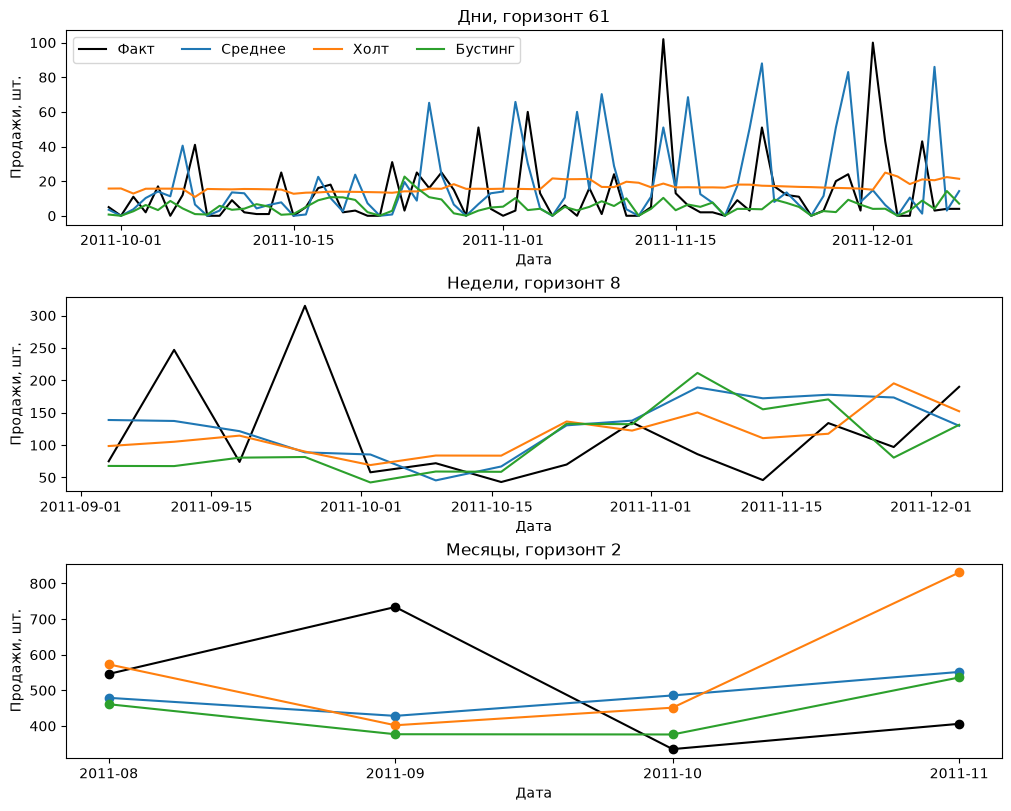

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), layout="constrained")
for ax, (frequency, (_, _, horizons, _)) in zip(axes, settings.items()):
    h = max(horizons)
    group = forecasts.loc[(forecasts["frequency"] == frequency) & (forecasts["horizon"] == h)]
    actual = group.drop_duplicates("date").set_index("date")["actual"]
    estimates = group.pivot(index="date", columns="model", values="forecast")
    marker = "o" if frequency == "Месяцы" else None
    ax.plot(actual, color="black", label="Факт", marker=marker)
    for name in models:
        ax.plot(estimates[name], label=name, marker=marker)
    ax.set(title=f"{frequency}, горизонт {h}", xlabel="Дата", ylabel="Продажи, шт.")
    if frequency == "Месяцы":
        ax.set_xticks(actual.index, actual.index.strftime("%Y-%m"))
axes[0].legend(ncol=4)
plt.show()

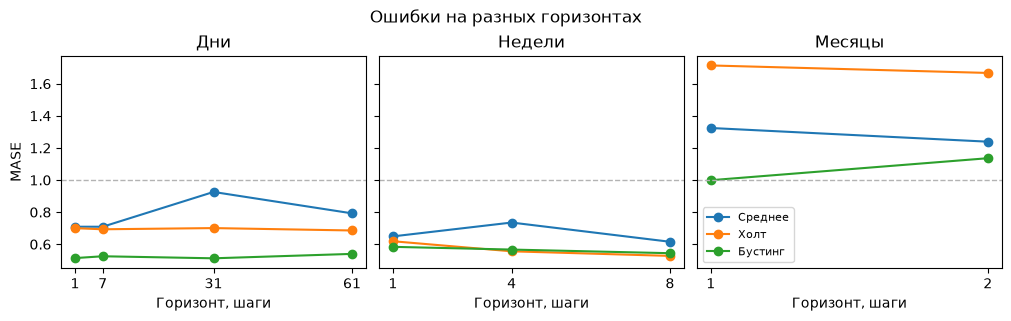

,frequency,horizon,model,n,MAE,MASE
2,Дни,1,Бустинг,70,11.46,0.51
5,Дни,7,Бустинг,70,11.71,0.53
8,Дни,31,Бустинг,70,11.43,0.51
11,Дни,61,Бустинг,70,12.04,0.54
14,Недели,1,Бустинг,14,67.64,0.58
16,Недели,4,Холт,14,64.41,0.56
19,Недели,8,Холт,14,61.11,0.53
23,Месяцы,1,Бустинг,4,134.86,1.00
26,Месяцы,2,Бустинг,4,153.35,1.14


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.1), sharey=True, layout="constrained")
for ax, (frequency, (_, _, horizons, _)) in zip(axes, settings.items()):
    group = scores.loc[scores["frequency"] == frequency]
    for name in models:
        line = group.loc[group["model"] == name]
        ax.plot(line["horizon"], line["MASE"], marker="o", label=name)
    ax.axhline(1, color="0.7", linestyle="--", linewidth=1)
    ax.set(title=frequency, xlabel="Горизонт, шаги", xticks=horizons)
axes[0].set_ylabel("MASE")
axes[-1].legend(fontsize=8)
fig.suptitle("Ошибки на разных горизонтах")
plt.show()

scores.loc[scores.groupby(["frequency", "horizon"], sort=False)["MASE"].idxmin()].round(2)

## Выводы

На днях бустинг лидирует на всех горизонтах. Его MAE меняется от 11,4 до 12,0 штуки. На графике для 61 шага видим, что крупные пики он занижает.

На неделях бустинг лучше на шаге 1, Холт на 4 и 8 шагах. У лучшей модели MASE здесь снижается с 0,58 до 0,53.

На месяцах лидирует бустинг. Его MASE на втором шаге вырастает примерно с 1 до 1,14. Тестовых месяцев всего четыре, а для прямого бустинга на два месяца из каждого окна получается только четыре пары признаков и цели.